#  Overview

This notebook demonstrates how to discover raw RADARSAT-1 scenes from the EODMS Search service (STAC), evaluate their coverage over an area of interest, submit scenes to the EODMS Processing service (OGC Processes) for Level-1 processing, and download the resulting image products.


## Finding data using the EODMS Search API

In [1]:
%matplotlib inline

import os
from pathlib import Path
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import contextily as ctx
from io import BytesIO

from shapely.geometry import shape
from pystac_client import Client

from eodms import aaa, Processes_API

We will search for RADARSAT-1 scenes over Montreal between May 1st and August 31st, 2007.

In [2]:
def get_bbox(geojson_path):
    """Extracts bounding box coordinates from an input vector data file"""
    gdf = gpd.read_file(geojson_path)
    if gdf.crs.to_epsg() != 4326:
        gdf = gdf.to_crs(4326)
    bbox = tuple([float(b) for b in gdf.total_bounds])

    return bbox

In [3]:
# date range for search
start_date = '2007-05-01'
end_date = '2007-08-31'

# creating bounding box from input GeoJSON to use as spatial filter
geojson_path = 'montreal-limites-administratives.geojson'
aoi_gdf = gpd.read_file(geojson_path)
bbox = get_bbox(geojson_path)
bbox

(-73.9966021388108, 45.3854030130529, -73.4738652778201, 45.7075796336657)

In [4]:
# List all items in collection within date range that intersect with bounding box
catalog_url = 'https://www.eodms-sgdot.nrcan-rncan.gc.ca/search'
collection = 'Radarsat-1-Raw'
catalog = Client.open(catalog_url)

search = catalog.search(
    collections=[collection],
    bbox=bbox,
    datetime=f'{start_date}/{end_date}',
    limit=100,
    method='GET'
)

all_items = search.item_collection()
print(f'{len(all_items)} total products found')

# Filter for Single Beam Mode only (ScanSAR is currently unsupported for L1 processing)
items = [item for item in all_items if not item.properties.get('beam_mode').startswith('ScanSAR')]
print(f'{len(items)} Single Beam products after filtering')

26 total products found
19 Single Beam products after filtering


Sorting the list of Radarsat-1-Raw products by percent coverage of GeoJSON AOI:

In [5]:
def calculate_coverage(item, aoi_gdf):
    "''Calculate the percent coverage of a STAC item footprint over a provided AOI geometry"""

    # default UTM zones
    utm_crs = aoi_gdf.estimate_utm_crs().to_epsg()
    aoi_gdf_utm = aoi_gdf.to_crs(utm_crs)

    # create GDF from STAC geometry and calculate intersection
    item_geom = shape(item.to_dict()['geometry'])
    item_gdf = gpd.GeoDataFrame([{'geometry': item_geom}], crs='EPSG:4326').to_crs(utm_crs)
    intersection = gpd.overlay(item_gdf, aoi_gdf_utm, how='intersection')
    
    # get AOI area 
    aoi_area = aoi_gdf_utm.geometry.area.sum()
    
    if len(intersection) > 0:
        intersection_area = intersection.geometry.area.sum()
        coverage_percent = float(round((intersection_area / aoi_area) * 100, 1))
    else:
        coverage_percent = 0.0
    
    return coverage_percent

In [6]:
def create_coverage_table(items, aoi_gdf):
    """Sorts all STAC items from a Radarsat-1-RAW collection search by percent coverage of an AOI"""
    
    dict_list = []
    for item in items:
        # calcualte percent coverage
        aoi_coverage = calculate_coverage(item, aoi_gdf)

        # metadata from item properties
        item_dict = item.to_dict()
        dict_list.append({
            'id': item_dict.get('id'),
            'coverage': aoi_coverage,
            'datetime': item_dict.get('properties').get('datetime'),
            'orbit_direction': item_dict.get('properties').get('sat:orbit_state'),
            'relative_orbit': item_dict.get('properties').get('sat:relative_orbit'),
            'beam_mnemonic': item_dict.get('properties').get('beam_mnemonic'),
            'polarizations': item_dict.get('properties').get('sar:polarizations')
        })

    # Return table with results
    coverage_table = pd.DataFrame(dict_list).sort_values(by='coverage', ascending=False)

    return coverage_table

In [7]:
coverage_table = create_coverage_table(items, aoi_gdf)
coverage_table[0:10]  # top 10 results by % coverage

,id,coverage,datetime,orbit_direction,relative_orbit,beam_mnemonic,polarizations
2,c0b6e1be-60ff-4886-ae81-0b31bcf868b5,100.0,2007-05-06T22:47:26.961000Z,ascending,20,F2,[HH]
4,8a8f02aa-4d9c-4d1d-99c5-5d9175456d6a,100.0,2007-05-06T22:47:30.268000Z,ascending,20,F2,[HH]
3,45f59331-c2a3-4f7c-8211-14883e548069,100.0,2007-05-06T22:47:29.754000Z,ascending,20,F2,[HH]
17,a788d533-8b7e-44ae-a15e-806c96061964,100.0,2007-08-25T10:49:21.026000Z,descending,227,S7,[HH]
8,3ace0f9a-e776-43ce-bc29-a94623a3f085,99.3,2007-05-30T22:47:26.750000Z,ascending,20,F2,[HH]
18,5b8430ab-498d-496c-ad82-e636fc225dfb,97.8,2007-08-25T10:49:22.396000Z,descending,227,S7,[HH]
7,3ace0f9a-e776-43ce-bc29-a94623a3f085,57.6,2007-05-30T22:47:19.375000Z,ascending,20,F2,[HH]
6,3addb92e-17ea-4802-85d1-208c1379bbb3,37.2,2007-05-20T22:39:04.805000Z,ascending,220,S2,[HH]
1,8a8f02aa-4d9c-4d1d-99c5-5d9175456d6a,33.8,2007-05-06T22:47:23.134000Z,ascending,20,F2,[HH]
16,5b8430ab-498d-496c-ad82-e636fc225dfb,19.1,2007-08-25T10:49:08.198000Z,descending,227,S7,[HH]


We will take the highest-coverage Standard Beam product (`beam_mnemonic='S*'`) for further processing, and visualize its footprint on the map below:

In [8]:
standard_beam_products = coverage_table[coverage_table['beam_mnemonic'].str.startswith('S')]
r1_product_id = standard_beam_products.iloc[0,0]
r1_item = [i for i in items if i.id == r1_product_id][0].to_dict()

In [9]:
def plot_item_footprint(item, aoi_gdf, figsize=(6, 6), add_basemap=True):
    """Display a STAC item footprint over a basemap with a provided AOI geometry."""
    
    # Create geodataframe of item footprint
    if type(item) != dict:
        item = item.to_dict()

    item_geom = shape(item.get('geometry'))
    item_gdf = gpd.GeoDataFrame([{'geometry': item_geom}], crs=4326)

    # Reproject both GDFs to Web Mercator for basemap
    item_gdf_mercator = item_gdf.to_crs(3857)
    aoi_gdf_mercator = aoi_gdf.to_crs(3857)
    
    # Create plot
    fig, ax = plt.subplots(figsize=figsize)
    
    # Plot AOI
    aoi_gdf_mercator.boundary.plot(ax=ax, color='red', linewidth=2, label='AOI')
    aoi_gdf_mercator.plot(ax=ax, alpha=0.2, color='red', edgecolor='red')
    
    # Plot item footprint
    item_gdf_mercator.boundary.plot(ax=ax, color='blue', linewidth=2, label='Item Footprint')
    item_gdf_mercator.plot(ax=ax, alpha=0.1, color='blue', edgecolor='blue')

    # Basemap tiles can fail on networks with TLS interception; keep plotting without tiles.
    if add_basemap:
        try:
            ctx.add_basemap(ax)
        except Exception as e:
            print(f"Basemap unavailable (SSL/network): {e}")
    
    # Add title and legend
    item_id = item.get('id')
    datetime = item.get('properties').get('datetime', 'N/A')
    
    ax.set_title(f'Product ID: {item_id}\n\nAcquisition Date: {datetime}', 
                 fontsize=12, pad=10)
    ax.legend(loc='upper right', fontsize=10)
    ax.set_xlabel('Easting')
    ax.set_ylabel('Northing')
    
    plt.tight_layout()
    
    return fig, ax

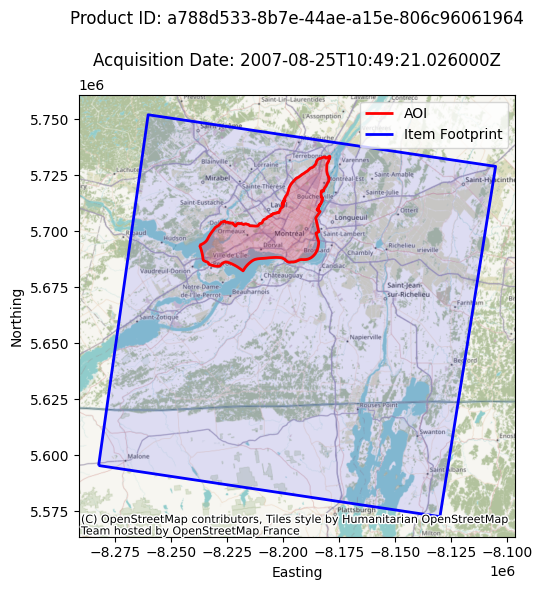

In [10]:
fig, ax = plot_item_footprint(r1_item, aoi_gdf)
plt.show()

Additional properties of the raw Radarsat-1 frame item are as follows:

In [11]:
r1_item.get('properties')

{'acquisition_orbit': 61624,
 'archive_facility': 'GATN',
 'beam_mnemonic': 'S7',
 'beam_mode': 'Standard',
 'dataset_id': 385657,
 'datetime': '2007-08-25T10:49:21.026000Z',
 'end_datetime': '2007-08-25T10:49:37.903+00:00',
 'sar:polarizations': ['HH'],
 'product:format': 'FRED',
 'sat:acquisition_station': 'GATN',
 'sat:orbit_state': 'descending',
 'sat:relative_orbit': 227,
 'segment_id': '83865389-3adf-4265-83b8-c981a7f7e1a0',
 'segment_start_datetime': '2007-08-25T10:48:54.742+00:00',
 'segment_stop_datetime': '2007-08-25T10:50:06.894+00:00',
 'start_datetime': '2007-08-25T10:49:21.026+00:00',
 'sar:frequency_band': 'C',
 'proj:code': 'EPSG:4326',
 'sar:beam_ids': ['S7'],
 'sar:center_frequency': 5.3}

Visualizing the quicklook thumbnail from the STAC item metadata, if available:

In [12]:
thumbnail_url = r1_item.get('properties').get('thumbnail')

try:
    response = requests.get(thumbnail_url)
    response.raise_for_status()
    
    # read JPEG image bytes with numpy
    img = mpimg.imread(BytesIO(response.content), format='jpg')
    
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(img, cmap='gray')
    ax.axis('off')
    ax.set_title(f"Quicklook: {r1_product_id}", fontsize=12, pad=10)
    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f"Failed to fetch thumbnail: {e}")

Failed to fetch thumbnail: Invalid URL 'None': No scheme supplied. Perhaps you meant https://None?


## Submitting orders to the EODMS Processes API

An authorization token is required to send certain requests to the Processes API, created using your EODMS username and password. These values must be exported as environment variables `EODMS_USERNAME` and `EODMS_PASSWORD` before obtaining a token via the `AAA_API` class.

The following cell shows how to load these variables from a `.credentials` file with a structure of:

```bash
EODMS_USERNAME="foo"
EODMS_PASSWORD="bar"
```

In [13]:
credentials_path = '../.credentials'

if os.path.exists(credentials_path):
    with open(credentials_path, 'r') as f:
        for line in f:
            line = line.strip()
            if line:
                key, value = line.split('=', 1)
                value = value.strip('"').strip("'")
                os.environ[key] = value
    print('EODMS credentials loaded as environment variables from .credentials file')
    aaa_api = aaa.AAA_API(os.environ.get('EODMS_USERNAME'), os.environ.get('EODMS_PASSWORD'))
else:
    print('No .credentials file found. Please set EODMS_USERNAME and EODMS_PASSWORD environment variables manually.')

EODMS credentials loaded as environment variables from .credentials file


We can find the required input structure for a given process using the `processing/processes/{processID}` endpoint:

In [14]:
proc_api = Processes_API(aaa_api=aaa_api, environment='prod')
proc_api.print_process_inputs('Radarsat1GAMMAL1SLC')

{
    "end_time": {
        "minOccurs": 1,
        "title": "end time",
        "description": "End time of FRED dataset extraction",
        "type": "string",
        "maxOccurs": 1
    },
    "lookup_table": {
        "enum": [
            "ice",
            "mixed",
            "point-target",
            "constant-beta"
        ],
        "title": "lookup table",
        "description": "lookup table to use for processing (16-bit mode only)",
        "minOccurs": 0,
        "maxOccurs": 1,
        "default": "mixed"
    },
    "start_time": {
        "title": "start time",
        "maxOccurs": 1,
        "minOccurs": 1,
        "type": "string",
        "description": "Start time of FRED dataset extraction"
    },
    "uuid": {
        "minOccurs": 1,
        "description": "The unique identifier of the L0 dataset",
        "maxOccurs": 1,
        "type": "string",
        "title": "uuid"
    }
}


{'title': 'Radarsat-1 GAMMA L1 SLC',
 'description': "Generate a Radarsat-1 L1 product in GAMMA SLC format - Maximum of 2 frames per process request - Use 'start_time' and 'stop_time' to limit the frames processed",
 'keywords': ['Radarsat-1', 'FRED', 'SLC', 'GAMMA', 'L1'],
 'id': 'Radarsat1GAMMAL1SLC',
 'version': '0.0.1',
 'jobControlOptions': ['async-execute'],
 'outputTransmission': ['value'],
 'links': [{'href': 'https://eodms-sgdot.nrcan-rncan.gc.ca/processing/processes/Radarsat1GAMMAL1SLC',
   'rel': 'self',
   'type': 'application/json',
   'title': 'OGC API Process Descriptions'},
  {'href': 'https://eodms-sgdot.nrcan-rncan.gc.ca/processing/jobs',
   'rel': 'http://www.opengis.net/def/rel/ogc/1.0/job-list',
   'type': 'application/json',
   'title': 'OGC API processes job list'},
  {'href': 'https://eodms-sgdot.nrcan-rncan.gc.ca/processing/processes/Radarsat1GAMMAL1SLC/execute',
   'rel': 'http://www.opengis.net/def/rel/ogc/1.0/execute',
   'type': 'application/json',
   'titl

The `Radarsat-1-Raw` collection represents individual R1 raw scenes/frames. The source raw data is stored in FRED (Framed Raw Expanded Data) format, where each entry represents a much larger segment/swath comprising of multiple frames.

To avoid processing unnecessary frames within a swath that don't overlap our study area, the Processes API accepts `start_time` and `end_time` arguments that correspond to when individual frames were imaged. These values along with the FRED segment ID for each frame are stored in the STAC item metadata.

In [15]:
segment_id = r1_item.get('properties').get('segment_id')
img_start = r1_item.get('properties').get('start_datetime')
img_end = r1_item.get('properties').get('end_datetime')

The following function sends a POST request to the `/processing/processes/{processID}/execution` endpoint given a FRED segment UUID and specific process ID with some other optional processing arguments:

In [16]:
order = proc_api.submit_r1_process(
  segment_id=segment_id,
  process_id='Radarsat1GAMMAL1SLC',
  start_time=img_start,
  end_time=img_end,
)

job_id = order['jobID']
order

{'processID': 'Radarsat1GAMMAL1SLC',
 'type': 'process',
 'jobID': '12f60e1f-f5e8-47dd-a39a-6bdaf9156134',
 'status': 'accepted',
 'created': '2026-10-26T15:37:21.386570Z',
 'progress': 0,
 'links': [{'href': 'https://eodms-sgdot.nrcan-rncan.gc.ca/processing/jobs/12f60e1f-f5e8-47dd-a39a-6bdaf9156134',
   'rel': 'status',
   'type': 'application/json',
   'title': 'Job Status'},
  {'href': 'https://eodms-sgdot.nrcan-rncan.gc.ca/processing/jobs/12f60e1f-f5e8-47dd-a39a-6bdaf9156134/results',
   'rel': 'http://www.opengis.net/def/rel/ogc/1.0/results',
   'type': 'application/json',
   'title': 'OGC Processes API job results'}]}

## Monitoring job status

The status of each job submitted to the `/processing/processes/{processID}/execution` endpoint is recorded at `/jobs/{jobID}`.

We will send GET requests to the job's status endpoint at a regular interval until the L1 product has finished processing:

In [17]:
%%time
status = proc_api.poll_job_status(job_id, interval=60, timeout=3600)
status

CPU times: total: 359 ms
Wall time: 7min


{'processID': 'Radarsat1GAMMAL1SLC',
 'type': 'process',
 'jobID': '12f60e1f-f5e8-47dd-a39a-6bdaf9156134',
 'status': 'successful',
 'message': 'success',
 'created': '2026-10-26T15:37:21.386570Z',
 'started': '2026-10-26T15:37:22.394881Z',
 'finished': '2026-10-26T15:44:06.840447Z',
 'updated': '2026-10-26T15:44:06.840447Z',
 'progress': 100,
 'links': [{'href': 'https://eodms-sgdot.nrcan-rncan.gc.ca/processing/jobs/12f60e1f-f5e8-47dd-a39a-6bdaf9156134',
   'rel': 'self',
   'type': 'application/json',
   'title': 'Job Status'},
  {'href': 'https://eodms-sgdot.nrcan-rncan.gc.ca/processing/jobs/12f60e1f-f5e8-47dd-a39a-6bdaf9156134/results',
   'rel': 'http://www.opengis.net/def/rel/ogc/1.0/results',
   'type': 'application/json',
   'title': 'OGC Processes API job results'}]}

## Accessing resulting L1 products

All output files referenced by `/processing/jobs/{jobId}/results` can be downloaded from an open-access AWS S3 bucket:

In [18]:
%%time
if not os.path.exists('./data'):
    os.makedirs('./data')

downloaded = proc_api.download_job_results(job_id, out_dir=f'./data/{job_id}')
for download in downloaded:
    print(download)

./data/12f60e1f-f5e8-47dd-a39a-6bdaf9156134\RS1_L1SLC_S7_20070825_104921_104937_W027523_1.slc.par
./data/12f60e1f-f5e8-47dd-a39a-6bdaf9156134\RS1_L1SLC_S7_20070825_104921_104937_W027523_1.slc.hdr
./data/12f60e1f-f5e8-47dd-a39a-6bdaf9156134\RS1_L1SLC_S7_20070825_104921_104937_W027523_1_antenna_pattern.dat
./data/12f60e1f-f5e8-47dd-a39a-6bdaf9156134\RS1_L1SLC_S7_20070825_104921_104937_W027523_1_incidence_angle.hdr
./data/12f60e1f-f5e8-47dd-a39a-6bdaf9156134\UserLicenseAgreement.pdf
./data/12f60e1f-f5e8-47dd-a39a-6bdaf9156134\RS1_L1SLC_S7_20070825_104921_104937_W027523_1.slc
./data/12f60e1f-f5e8-47dd-a39a-6bdaf9156134\RS1_L1SLC_S7_20070825_104921_104937_W027523_1.stac.json
./data/12f60e1f-f5e8-47dd-a39a-6bdaf9156134\README-LISEZMOI.txt
./data/12f60e1f-f5e8-47dd-a39a-6bdaf9156134\RS1_L1SLC_S7_20070825_104921_104937_W027523_1_antenna_pattern.hdr
./data/12f60e1f-f5e8-47dd-a39a-6bdaf9156134\RS1_L1SLC_S7_20070825_104921_104937_W027523_1_intensity_Beta.vrt
./data/12f60e1f-f5e8-47dd-a39a-6bdaf91